# Long-tailed images: the same model under different class priors

A classifier trained on a long-tailed image dataset can be evaluated on a set with the same long tail, or
on a balanced one. The same model gets an accuracy near 0.92 on one and near 0.66 on the other. This
notebook uses the predictions of ResNet-32 models trained on CIFAR-10-LT to show which measures change
with the class prior and which do not, and how that can change the verdict when a baseline is compared
with a method designed for imbalance. The balanced test set lets us do this cleanly: we can *simulate* any
class prior by reweighting it, without new data and without sampling noise from small splits.

In [1]:
# Installs the package only where it is missing (for example in Colab).
import importlib.util
if importlib.util.find_spec("aggmetrics") is None:
    %pip install -q aggmetrics scikit-learn matplotlib pandas

In [2]:
import io
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from aggmetrics import IndicatorMatrix, get_measure, pareto_dominance

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "figure.dpi": 100,
})

## The models and the data

CIFAR-10-LT keeps 4490 training images of class 0 and only 42 of class 9: an imbalance ratio of 100.
Two ResNet-32 models were trained for 200 epochs, five seeds each: one with the usual cross-entropy
(`ce`) and one with the logit-adjusted loss (`logit_adj`, Menon et al., 2021), which accounts for the
class prior in training. The file in the repository holds the **predictions** of those models and the
true labels, on two sets:

- a long-tailed **validation** split, drawn from the training distribution (1241 images, a new draw for
  each seed);
- the standard CIFAR-10 **test** set, which is balanced: 1000 images per class.

Images and logits are not included; the origin of the models and the citations are in the README next to
the file.

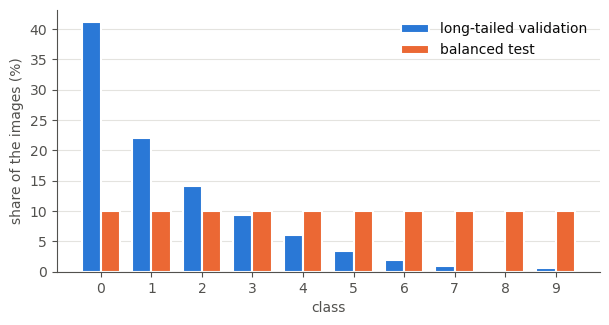

In [3]:
URL = "https://raw.githubusercontent.com/rcprati/aggmetrics/main/examples/data/cifar10lt/predictions.npz"
local = Path("../data/cifar10lt/predictions.npz")
source = local if local.exists() else io.BytesIO(urllib.request.urlopen(URL, timeout=60).read())
z = np.load(source)

loss, seed, y_test = z["loss"], z["seed"], z["y_test"].astype(int)

def run_index(name, s):
    return int(np.flatnonzero((loss == name) & (seed == s))[0])

def im_of(name, s, split):
    i = run_index(name, s)
    y = y_test if split == "test" else z["y_val"][i].astype(int)
    return IndicatorMatrix(y, z["pred_" + split][i].astype(int), task="multiclass", n_classes=10)

runs = {(name, s, split): im_of(name, s, split)
        for name in ("ce", "logit_adj") for s in range(5) for split in ("val", "test")}

val_share = np.bincount(z["y_val"][0].astype(int), minlength=10) / z["y_val"].shape[1]
test_share = np.bincount(y_test, minlength=10) / len(y_test)

fig, ax = plt.subplots(figsize=(7, 3.4))
x = np.arange(10)
w = 0.38
ax.bar(x - w / 2, 100 * val_share, w, color=BLUE, edgecolor="white", linewidth=1.5, label="long-tailed validation")
ax.bar(x + w / 2, 100 * test_share, w, color=ORANGE, edgecolor="white", linewidth=1.5, label="balanced test")
ax.set_xticks(x)
ax.set_xlabel("class")
ax.set_ylabel("share of the images (%)")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False)
plt.show()

## The same model, two accuracies

Take the cross-entropy model of seed 0:

In [4]:
ce_val, ce_test = runs[("ce", 0, "val")], runs[("ce", 0, "test")]
pd.DataFrame({
    "long-tailed validation": {"accuracy": ce_val.accuracy(), "macro-recall": ce_val.compute("recall", "macro")},
    "balanced test": {"accuracy": ce_test.accuracy(), "macro-recall": ce_test.compute("recall", "macro")},
}).round(3)

,long-tailed validation,balanced test
accuracy,0.917,0.65
macro-recall,0.699,0.65


The accuracy goes from 0.92 on the validation split to 0.65 on the test set. Nothing about the model
changed. Class 0 is 41% of the validation images and the model gets almost all of them right, so accuracy
there is mostly the accuracy on the head classes. On the test set every class counts for a tenth.

On a set with the same number of examples in every class, accuracy and macro-recall are the same number,
because accuracy is then the average of the per-class recalls. On the long-tailed set they are far apart:

In [5]:
rows = []
for (name, s, split), im in runs.items():
    rows.append(dict(model=name, seed=s, split=split, accuracy=im.accuracy(),
                     macro_recall=im.compute("recall", "macro")))
metrics = pd.DataFrame(rows)
metrics["gap"] = metrics.accuracy - metrics.macro_recall

test_rows = metrics[metrics.split == "test"]
assert np.allclose(test_rows.accuracy, test_rows.macro_recall, atol=1e-12)
print("balanced test:  accuracy equals macro-recall in all 10 runs (largest difference "
      f"{float(test_rows.gap.abs().max()):.1e})")
print("long-tailed validation: mean gap between accuracy and macro-recall =",
      round(float(metrics[metrics.split == "val"].gap.mean()), 3))

balanced test:  accuracy equals macro-recall in all 10 runs (largest difference 1.1e-16)
long-tailed validation: mean gap between accuracy and macro-recall = 0.204


## Changing the prior without new data

The comparison above mixes two things: the class prior, and the fact that the validation images come from
the CIFAR training split while the test images come from the test split. Because the test set is balanced,
we can separate them. A balanced test set has the same number of images in every class, so weighting the
images of class $k$ by $\pi_k K$ (with $K=10$ classes) gives the confusion matrix the model would show
if the classes had prior $\pi$. Then:

- the recall of each class is **unchanged**, exactly, because it only looks inside the class;
- accuracy becomes $\sum_k \pi_k\,\mathrm{recall}_k$;
- precision and specificity change, because they depend on the images of the *other* classes. They are
  recomputed from the reweighted counts, using the measures of the library.

The prior will follow the geometric profile of CIFAR-10-LT: $\pi_k \propto \rho^{-k/9}$, where $\rho$ is the
imbalance ratio between the first and the last class ($\rho = 1$ is balanced).

In [6]:
def confusion(y, pred):
    C = np.zeros((10, 10))
    np.add.at(C, (y, pred), 1)
    return C                                  # C[j, k]: true class j, predicted class k

def geometric_prior(rho):
    w = rho ** (-np.arange(10) / 9)
    return w / w.sum()

def reweighted_counts(C, pi):
    W = C * (pi * 10)[:, None]                # the rows of a balanced test set carry the weight pi_k * K
    tp = np.diag(W)
    fn = W.sum(axis=1) - tp
    fp = W.sum(axis=0) - tp
    tn = W.sum() - tp - fn - fp
    return tp, fp, fn, tn

def reweighted_macro(C, pi, measure):
    values = [get_measure(measure)(*c) for c in zip(*reweighted_counts(C, pi))]
    return float(np.nanmean(values))

def reweighted_accuracy(C, pi):
    return float(np.trace(C * (pi * 10)[:, None]) / (C * (pi * 10)[:, None]).sum())

def test_confusion(name, s):
    return confusion(y_test, z["pred_test"][run_index(name, s)].astype(int))

# with the uniform prior, the reweighted values are those of IndicatorMatrix
C0 = test_confusion("ce", 0)
assert np.isclose(reweighted_macro(C0, geometric_prior(1), "precision"),
                  runs[("ce", 0, "test")].compute("precision", "macro"))
assert np.isclose(reweighted_accuracy(C0, geometric_prior(1)), runs[("ce", 0, "test")].accuracy())
print("uniform prior reproduces the direct computation")

uniform prior reproduces the direct computation


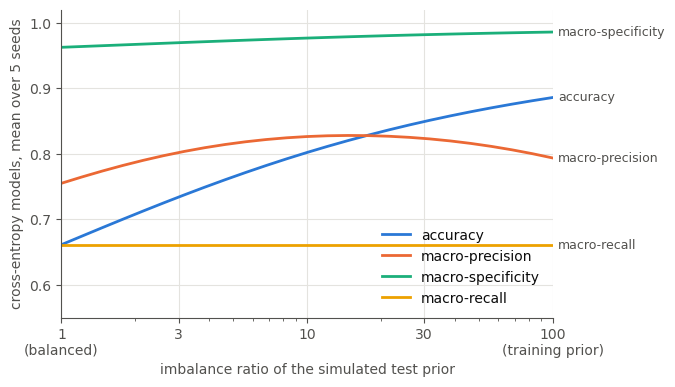

macro-recall is the same for every prior: 0.6611


In [7]:
rhos = np.geomspace(1, 100, 25)

def sweep(name):
    out = {m: [] for m in ("accuracy", "macro-recall", "macro-precision", "macro-specificity")}
    for rho in rhos:
        pi = geometric_prior(rho)
        per_seed = {m: [] for m in out}
        for s in range(5):
            C = test_confusion(name, s)
            per_seed["accuracy"].append(reweighted_accuracy(C, pi))
            per_seed["macro-recall"].append(reweighted_macro(C, pi, "recall"))
            per_seed["macro-precision"].append(reweighted_macro(C, pi, "precision"))
            per_seed["macro-specificity"].append(reweighted_macro(C, pi, "specificity"))
        for m in out:
            out[m].append(np.mean(per_seed[m]))
    return pd.DataFrame(out, index=rhos)

sweeps = {name: sweep(name) for name in ("ce", "logit_adj")}

fig, ax = plt.subplots(figsize=(7.5, 4))
ce_sweep = sweeps["ce"]
for column, color in (("accuracy", BLUE), ("macro-precision", ORANGE),
                      ("macro-specificity", AQUA), ("macro-recall", YELLOW)):
    ax.plot(rhos, ce_sweep[column], color=color, label=column)
    ax.text(rhos[-1] * 1.05, ce_sweep[column].iloc[-1], column, color=INK2, va="center", fontsize=9)
ax.set_xscale("log")
ax.set_xticks([1, 3, 10, 30, 100])
ax.set_xticklabels(["1\n(balanced)", "3", "10", "30", "100\n(training prior)"])
ax.set_xlim(1, 100)
ax.set_ylim(0.55, 1.02)
ax.set_xlabel("imbalance ratio of the simulated test prior")
ax.set_ylabel("cross-entropy models, mean over 5 seeds")
ax.legend(frameon=False, loc="lower right")
fig.subplots_adjust(right=0.78)
plt.show()

assert np.allclose(ce_sweep["macro-recall"], ce_sweep["macro-recall"].iloc[0], atol=1e-12)
print("macro-recall is the same for every prior:", round(float(ce_sweep["macro-recall"].iloc[0]), 4))

Macro-recall is exactly flat, at 0.661, as it must be. Accuracy rises from 0.661 to 0.886 as the prior
approaches the training prior, and specificity from 0.962 to 0.986. Precision does not move in one direction:
it rises to a maximum at moderate imbalance and falls again.

This also answers how much of the gap between 0.92 and 0.66 is the prior. The reweighted test set at the
*training prior* is the best simulation of the validation split that the test images allow:

In [8]:
rows = {}
for name in ("ce", "logit_adj"):
    at_training_prior, empirical = [], []
    for s in range(5):
        i = run_index(name, s)
        counts = z["class_counts"][i]
        at_training_prior.append(reweighted_accuracy(test_confusion(name, s), counts / counts.sum()))
        empirical.append(runs[(name, s, "val")].accuracy())
    rows[name] = {"test, balanced": float(np.mean([runs[(name, s, "test")].accuracy() for s in range(5)])),
                  "test reweighted to the training prior": float(np.mean(at_training_prior)),
                  "long-tailed validation (measured)": float(np.mean(empirical))}
pd.DataFrame(rows).round(3)

,ce,logit_adj
"test, balanced",0.661,0.709
test reweighted to the training prior,0.886,0.882
long-tailed validation (measured),0.919,0.914


For the cross-entropy models, going from the balanced test prior to the training prior takes the accuracy
from 0.661 to 0.886 on the *same* test images. The long-tailed validation split gives 0.919. So the prior
explains about 0.225 of the 0.258 gap; the remaining 0.03 comes from the validation images being a different
sample (and from a few images deciding the rare classes there), and it is the same size for both models.

## Which method is better depends on the prior

With the simulated priors we can put the two training losses on the same axis:

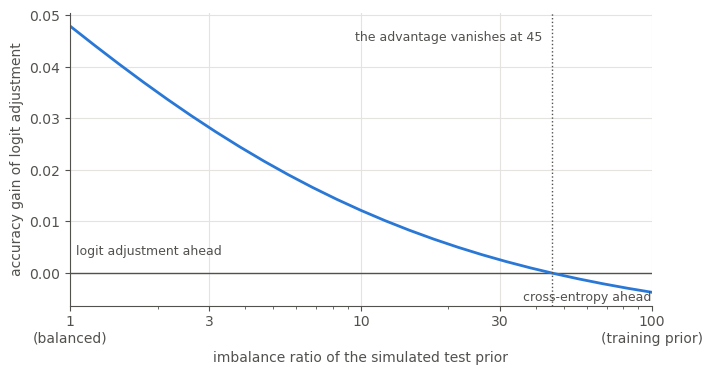

the sign changes at an imbalance ratio of about 45


,ce,logit_adj
balanced (rho = 1),0.661,0.709
training prior (rho = 100),0.886,0.882
macro-recall (any prior),0.661,0.709


In [9]:
diff = sweeps["logit_adj"]["accuracy"] - sweeps["ce"]["accuracy"]
sign_change = np.flatnonzero(np.diff(np.sign(diff.to_numpy())))[0]
r0, r1 = np.log(rhos[sign_change]), np.log(rhos[sign_change + 1])
d0, d1 = diff.iloc[sign_change], diff.iloc[sign_change + 1]
rho_star = float(np.exp(r0 + (r1 - r0) * d0 / (d0 - d1)))

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.axhline(0, color=INK2, linewidth=1)
ax.plot(rhos, diff, color=BLUE)
ax.axvline(rho_star, color=INK2, linewidth=1, linestyle=":")
ax.text(rho_star * 0.93, 0.045, f"the advantage vanishes at {rho_star:.0f}", color=INK2, fontsize=9, ha="right")
ax.text(1.05, 0.0035, "logit adjustment ahead", color=INK2, fontsize=9)
ax.text(100, -0.0035, "cross-entropy ahead", color=INK2, fontsize=9, ha="right", va="top")
ax.set_xscale("log")
ax.set_xticks([1, 3, 10, 30, 100])
ax.set_xticklabels(["1\n(balanced)", "3", "10", "30", "100\n(training prior)"])
ax.set_xlim(1, 100)
ax.set_xlabel("imbalance ratio of the simulated test prior")
ax.set_ylabel("accuracy gain of logit adjustment")
plt.show()
print(f"the sign changes at an imbalance ratio of about {rho_star:.0f}")

pd.DataFrame({name: {"balanced (rho = 1)": sweeps[name]["accuracy"].iloc[0],
                     "training prior (rho = 100)": sweeps[name]["accuracy"].iloc[-1],
                     "macro-recall (any prior)": sweeps[name]["macro-recall"].iloc[0]}
              for name in ("ce", "logit_adj")}).round(3)

Logit adjustment is better on a balanced test set (0.709 against 0.661), and its advantage shrinks as the
prior gets more skewed until the sign of the difference changes, at an imbalance ratio of about 45; at the
training prior (100), cross-entropy is slightly ahead (0.886 against 0.882). Both are right, about different questions: accuracy under a prior is the average of
the per-class recalls weighted by that prior. A method that raises the recall of the rare classes gains
weight when the rare classes matter, and loses nothing it can see when they are 1% of the data. This is why
the long-tailed validation set could not separate the two (accuracy 0.919 against 0.914, in the same order
as the simulation at the training prior), while the balanced test set ranks them in every seed:

In [10]:
test_acc = metrics[metrics.split == "test"].pivot(index="seed", columns="model", values="accuracy")
print(test_acc.round(4).to_string())
assert test_acc["logit_adj"].min() > test_acc["ce"].max()
print("\nevery logit-adjusted run is above every cross-entropy run on the balanced test set:",
      round(float(test_acc["logit_adj"].min()), 4), ">", round(float(test_acc["ce"].max()), 4))

model      ce  logit_adj
seed                    
0      0.6498     0.7127
1      0.6619     0.7036
2      0.6590     0.7132
3      0.6736     0.7146
4      0.6614     0.7010

every logit-adjusted run is above every cross-entropy run on the balanced test set: 0.701 > 0.6736


## The validation set as an empirical check

Recall of a class does not depend on the prior, so the recall per class should be about the same on the
long-tailed validation set and on the test set. It is close for the frequent classes, and not for the
rare ones:

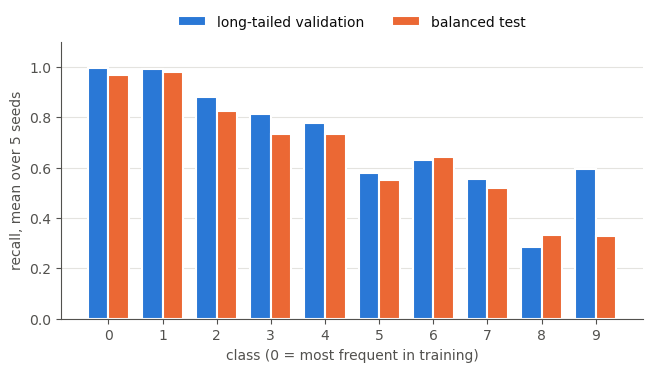

largest difference in recall, classes 0-4: 0.079
largest difference in recall, class 9    : 0.264


In [11]:
def mean_recall(name, split):
    return np.mean([runs[(name, s, split)].parts("recall", "macro") for s in range(5)], axis=0)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.bar(x - w / 2, mean_recall("ce", "val"), w, color=BLUE, edgecolor="white", linewidth=1.5,
       label="long-tailed validation")
ax.bar(x + w / 2, mean_recall("ce", "test"), w, color=ORANGE, edgecolor="white", linewidth=1.5,
       label="balanced test")
ax.set_xticks(x)
ax.set_xlabel("class (0 = most frequent in training)")
ax.set_ylabel("recall, mean over 5 seeds")
ax.set_ylim(0, 1.1)
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
plt.show()

diff_recall = np.abs(mean_recall("ce", "val") - mean_recall("ce", "test"))
print("largest difference in recall, classes 0-4:", round(float(diff_recall[:5].max()), 3))
print("largest difference in recall, class 9    :", round(float(diff_recall[9]), 3))

The recalls agree within 0.08 for classes 0 to 4. For the rare classes the validation split is a poor
guide: each seed has between 2 and 10 validation images of classes 8 and 9, so one image moves their recall
by 10 to 50 points.

## How uncertain are these numbers?

A bootstrap makes that explicit. Resampling the images of each class with replacement gives an interval for
a recall. On the validation split of seed 0, the rare classes give:

In [12]:
rng = np.random.default_rng(0)
B = 2000

def bootstrap_mean(values, rng=rng, B=B):
    n = len(values)
    means = values[rng.integers(0, n, (B, n))].mean(axis=1)
    return np.percentile(means, [2.5, 97.5])

ce_val_i = run_index("ce", 0)
yv, pv = z["y_val"][ce_val_i].astype(int), z["pred_val"][ce_val_i].astype(int)
rows = []
for k in (7, 8, 9):
    ok = (pv[yv == k] == k).astype(float)
    lo, hi = bootstrap_mean(ok)
    rows.append(dict(cls=k, validation_images=len(ok), recall=ok.mean(), ci_low=lo, ci_high=hi))
pd.DataFrame(rows).set_index("cls").round(3)

,validation_images,recall,ci_low,ci_high
cls,,,,
7,11,0.727,0.455,1.0
8,3,0.333,0.000,1.0
9,8,0.250,0.000,0.5


With 3 images in class 8 the interval is the whole range from 0 to 1. On the balanced test set each class
has 1000 images, and the same bootstrap is tight. Because both models are evaluated on the *same* test
images, we can bootstrap the **difference** in recall between logit adjustment and cross-entropy, class by
class (seed 0), and see where the methods really differ:

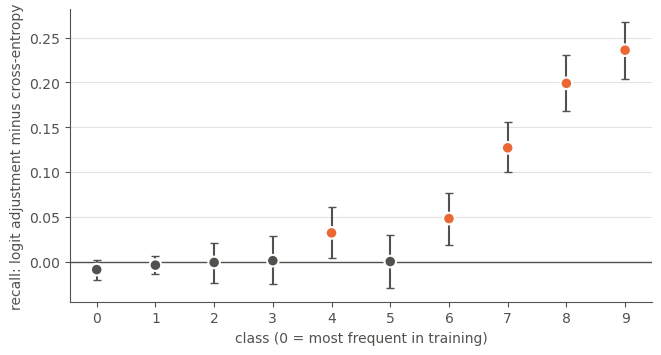

,cross_entropy,logit_adj,difference,ci_low,ci_high,differs
cls,,,,,,
0,0.966,0.957,-0.009,-0.021,0.002,False
1,0.981,0.977,-0.004,-0.014,0.006,False
2,0.827,0.826,-0.001,-0.024,0.021,False
3,0.746,0.747,0.001,-0.025,0.029,False
4,0.714,0.746,0.032,0.004,0.061,True
5,0.535,0.535,0.000,-0.030,0.030,False
6,0.636,0.684,0.048,0.018,0.076,True
7,0.517,0.644,0.127,0.100,0.156,True
8,0.291,0.490,0.199,0.168,0.231,True


In [13]:
ce_ok = z["pred_test"][run_index("ce", 0)].astype(int) == y_test
la_ok = z["pred_test"][run_index("logit_adj", 0)].astype(int) == y_test

rows = []
for k in range(10):
    d = la_ok[y_test == k].astype(float) - ce_ok[y_test == k].astype(float)
    lo, hi = bootstrap_mean(d)
    rows.append(dict(cls=k, cross_entropy=ce_ok[y_test == k].mean(), logit_adj=la_ok[y_test == k].mean(),
                     difference=d.mean(), ci_low=lo, ci_high=hi))
table = pd.DataFrame(rows).set_index("cls")
table["differs"] = (table.ci_low > 0) | (table.ci_high < 0)

fig, ax = plt.subplots(figsize=(7.5, 3.8))
colors = [ORANGE if d else INK2 for d in table.differs]
ax.axhline(0, color=INK2, linewidth=1)
ax.errorbar(table.index, table.difference, yerr=[table.difference - table.ci_low, table.ci_high - table.difference],
            fmt="none", ecolor=INK2, elinewidth=1.5, capsize=3, zorder=2)
ax.scatter(table.index, table.difference, c=colors, s=70, zorder=3, edgecolor="white", linewidth=1.5)
ax.set_xticks(range(10))
ax.set_xlabel("class (0 = most frequent in training)")
ax.set_ylabel("recall: logit adjustment minus cross-entropy")
ax.grid(axis="x", visible=False)
plt.show()
table.round(3)

For seed 0, logit adjustment improves the recall of classes 4 and 6 to 9, by up to 0.24, and the interval of
none of those includes zero (orange). On the frequent classes the differences are small and their intervals
contain zero: class 0 loses 0.009, within noise. Averaged over the five seeds, class 0 goes from 0.965
to 0.951.

Because the head gives up a little and the tail gains a lot, the two models are not ordered on every
class, and `pareto_dominance` says so:

In [14]:
pareto_dominance(runs[("ce", 0, "test")], runs[("logit_adj", 0, "test")])

'incomparable'

## What to report

- State the **class prior of the evaluation set** next to the number. An accuracy of 0.92 and an accuracy of
  0.66 can describe the same model, and a balanced test set can be reweighted to any other prior.
- **Recall per class does not depend on the prior; accuracy, precision and specificity do.** Report per-class
  recall, with the number of images behind each, and the macro-recall on a balanced set (on such a set it
  equals accuracy).
- When comparing a baseline with a method for imbalance, say **for which prior** the comparison holds: here
  the ranking changes between a balanced prior and the training prior.
- Put an **interval** on rare-class recalls. A long-tailed validation split with 3 to 10 images in a class
  cannot rank two methods; a balanced test set with 1000 can.
- When two methods trade head for tail, `pareto_dominance` returns `'incomparable'`, and the choice depends
  on which classes matter.

Next: thresholds and degenerate optima, soft labels, and custom measures.